In [1]:
%reload_ext autoreload
%autoreload 2

## **Trabajo Práctico 2 - Reconstrucción 3D**

In [40]:
import os
import pickle
import cv2
import numpy as np
import utils
import matplotlib.pyplot as plt

CARPETA_CALIB = "../data/calib"
CARPETA_CAPTURAS = "../data/captures"

In [36]:
%pip install stereodemo

Note: you may need to restart the kernel to use updated packages.


### ***1. Calibración y rectificación estéreo***

#### Calibración de las cámaras

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
La calibración se realizó en clase con `calib-stereo`, la herramienta proporcionada por la cátedra. Los resultados se guardaron en archivos `.pkl`, que cargamos en este notebook para utilizarlos en la reconstrucción.
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Para calibrar el sistema se utilizaron pares de imágenes de un tablero observado desde distintas posiciones y orientaciones. La geometría conocida del tablero permite establecer correspondencias entre las coordenadas 3D de sus esquinas y sus posiciones en las imágenes. A partir de estas correspondencias se estiman los parámetros de ambas cámaras y la relación espacial entre ellas.
</p>
Para cada cámara se obtiene una matriz intrínseca:

$$
K =
\begin{bmatrix}
f_x & 0 & p_x \\
0 & f_y & p_y \\
0 & 0 & 1
\end{bmatrix},
$$
 
<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
donde <i>f<sub>x</sub></i> y <i>f<sub>y</sub></i> representan las distancias focales en píxeles, y (<i>p<sub>x</sub></i>, <i>p<sub>y</sub></i>) indica la posición del punto principal. También se estiman los coeficientes de distorsión, que modelan las desviaciones introducidas por la lente respecto del modelo pinhole. En nuestra calibración se almacenan cinco coeficientes, en el orden (<i>k<sub>1</sub></i>, <i>k<sub>2</sub></i>, <i>p<sub>1</sub></i>, <i>p<sub>2</sub></i>, <i>k<sub>3</sub></i>): tres corresponden a la distorsión radial y dos a la tangencial.
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
La calibración estéreo estima, además, la rotación <i>R</i> y la traslación <i>T</i> relativas entre las cámaras. Estos parámetros permiten transformar las coordenadas de un punto desde el sistema de la cámara izquierda al de la derecha:
</p>

$$
X_{\mathrm{der}} = R X_{\mathrm{izq}} + T.
$$

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
La distancia entre los centros de las cámaras, denominada <i>baseline</i>, se calcula como <i>B</i> = ‖<i>T</i>‖. La escala métrica queda determinada por el tamaño físico del cuadrado ingresado durante la calibración: si este se expresa en milímetros, la traslación también queda expresada en esa unidad. Asimismo, se obtienen las matrices esencial <i>E</i> y fundamental <i>F</i>, que describen la geometría epipolar del sistema.
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
A continuación, cargamos los parámetros desde <code>stereo_calibration.pkl</code> y los resultados de rectificación desde <code>stereo_maps.pkl</code>, y mostramos los valores obtenidos.
</p>


In [4]:
with open("../data/stereo_calibration.pkl", "rb") as f:
    calib_pkl = pickle.load(f)

with open("../data/stereo_maps.pkl", "rb") as f:
    mapas_pkl = pickle.load(f)

ancho, alto = calib_pkl["image_size"]
baseline_mm = np.linalg.norm(calib_pkl["T"])

print(f"Resolución de cada cámara: {ancho} × {alto} píxeles")
print(f"Baseline: {baseline_mm:.4f} mm")

parametros = [
    ("Matriz intrínseca izquierda K", "left_K"),
    ("Distorsión izquierda [k1, k2, p1, p2, k3]", "left_dist"),
    ("Matriz intrínseca derecha K", "right_K"),
    ("Distorsión derecha [k1, k2, p1, p2, k3]", "right_dist"),
    ("Rotación relativa R", "R"),
    ("Traslación relativa T (mm)", "T"),
    ("Matriz esencial E", "E"),
    ("Matriz fundamental F", "F"),
]

with np.printoptions(precision=5, suppress=False):
    for descripcion, clave in parametros:
        print(f"\n{descripcion}:")
        print(calib_pkl[clave])

Resolución de cada cámara: 1920 × 1080 píxeles
Baseline: 59.8382 mm

Matriz intrínseca izquierda K:
[[592.85926   0.      958.13416]
 [  0.      590.30506 558.32698]
 [  0.        0.        1.     ]]

Distorsión izquierda [k1, k2, p1, p2, k3]:
[[ 4.97460e-03 -2.41411e-02  2.04411e-05 -5.93168e-04  3.84636e-03]]

Matriz intrínseca derecha K:
[[592.85164   0.      950.28608]
 [  0.      590.4396  543.67339]
 [  0.        0.        1.     ]]

Distorsión derecha [k1, k2, p1, p2, k3]:
[[ 0.00232 -0.02265 -0.00031 -0.00114  0.00351]]

Rotación relativa R:
[[ 9.99974e-01 -3.94819e-04  7.20356e-03]
 [ 3.81765e-04  9.99998e-01  1.81341e-03]
 [-7.20427e-03 -1.81061e-03  9.99972e-01]]

Traslación relativa T (mm):
[[-5.98369e+01]
 [-1.09342e-02]
 [ 3.96611e-01]]

Matriz esencial E:
[[-7.26392e-05 -3.96591e-01 -1.16531e-02]
 [-3.44799e-02 -1.08498e-01  5.98381e+01]
 [-1.19097e-02 -5.98368e+01 -1.08430e-01]]

Matriz fundamental F:
[[-3.04383e-10 -1.66904e-06  9.03211e-04]
 [-1.45073e-07 -4.58475e-07

#### Error de reproyección
FIJARNOS ESTO
El error de reproyección permite evaluar qué tan bien se ajustan los parámetros estimados a las observaciones utilizadas para calibrar. Para calcularlo se proyectan los puntos conocidos del tablero sobre las imágenes y se comparan sus posiciones predichas con las esquinas detectadas. 

Los archivos `.pkl` disponibles contienen los parámetros de calibración y los mapas de rectificación, pero no incluyen el error RMS informado por la herramienta. Por lo tanto, queda pendiente recuperar este valor del registro de la calibración realizada en clase para incorporarlo al informe.

In [5]:
#COSASSS

#### Rectificación estéreo

Para calcular la profundidad de un punto observado en la imagen izquierda, necesitamos encontrar su correspondiente en la derecha. La geometría epipolar restringe esta búsqueda a una línea (linea epipolar), que puede estar inclinada y verse curvada por la distorsión de la lente.

La rectificación puede interpretarse como un “giro” de las cámaras. Junto con la corrección de distorsión, transforma las imágenes para que las líneas epipolares queden horizontales y los puntos correspondientes se encuentren sobre una misma fila. Así, la búsqueda se reduce a comparar posiciones horizontales. La diferencia entre las coordenadas horizontales de un mismo punto se denomina disparidad.

Durante la calibración en clase se calcularon y almacenaron:

- `R1` y `R2`: rotaciones de rectificación.
- `P1` y `P2`: matrices de proyección de las cámaras rectificadas.
- `Q`: matriz que permite convertir coordenadas de imagen y disparidad
  en coordenadas 3D del sistema de la cámara izquierda rectificada.
- Los mapas de rectificación de ambas imágenes.

Cargamos estos resultados desde `stereo_maps.pkl` y aplicamos los mapas mediante `cv2.remap`. Luego mostramos los pares originales y rectificados.

In [6]:
rect = {
    "R_izq": mapas_pkl["R1"],
    "R_der": mapas_pkl["R2"],
    "P_izq": mapas_pkl["P1"],
    "P_der": mapas_pkl["P2"],
    "Q": mapas_pkl["Q"],
    "mapa_izq": (
        mapas_pkl["left_map_x"],
        mapas_pkl["left_map_y"],
    ),
    "mapa_der": (
        mapas_pkl["right_map_x"],
        mapas_pkl["right_map_y"],
    ),
}

with np.printoptions(precision=8, suppress=False):
    for clave in ["R1", "R2", "P1", "P2", "Q"]:
        print(f"\n{clave}:")
        print(mapas_pkl[clave])


R1:
[[ 9.99999814e-01 -2.00079755e-04  5.75857423e-04]
 [ 1.99557762e-04  9.99999569e-01  9.06376416e-04]
 [-5.76038523e-04 -9.06261330e-04  9.99999423e-01]]

R2:
[[ 9.99978017e-01  1.82729861e-04 -6.62806297e-03]
 [-1.88736958e-04  9.99999572e-01 -9.05698409e-04]
 [ 6.62789463e-03  9.06929460e-04  9.99977624e-01]]

P1:
[[591.45692233   0.         956.1940918    0.        ]
 [  0.         591.45692233 551.47379303   0.        ]
 [  0.           0.           1.           0.        ]]

P2:
[[ 5.91456922e+02  0.00000000e+00  9.56194092e+02 -3.53917009e+04]
 [ 0.00000000e+00  5.91456922e+02  5.51473793e+02  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00  0.00000000e+00]]

Q:
[[ 1.00000000e+00  0.00000000e+00  0.00000000e+00 -9.56194092e+02]
 [ 0.00000000e+00  1.00000000e+00  0.00000000e+00 -5.51473793e+02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  5.91456922e+02]
 [ 0.00000000e+00  0.00000000e+00  1.67117405e-02 -0.00000000e+00]]


Par estéreo 0


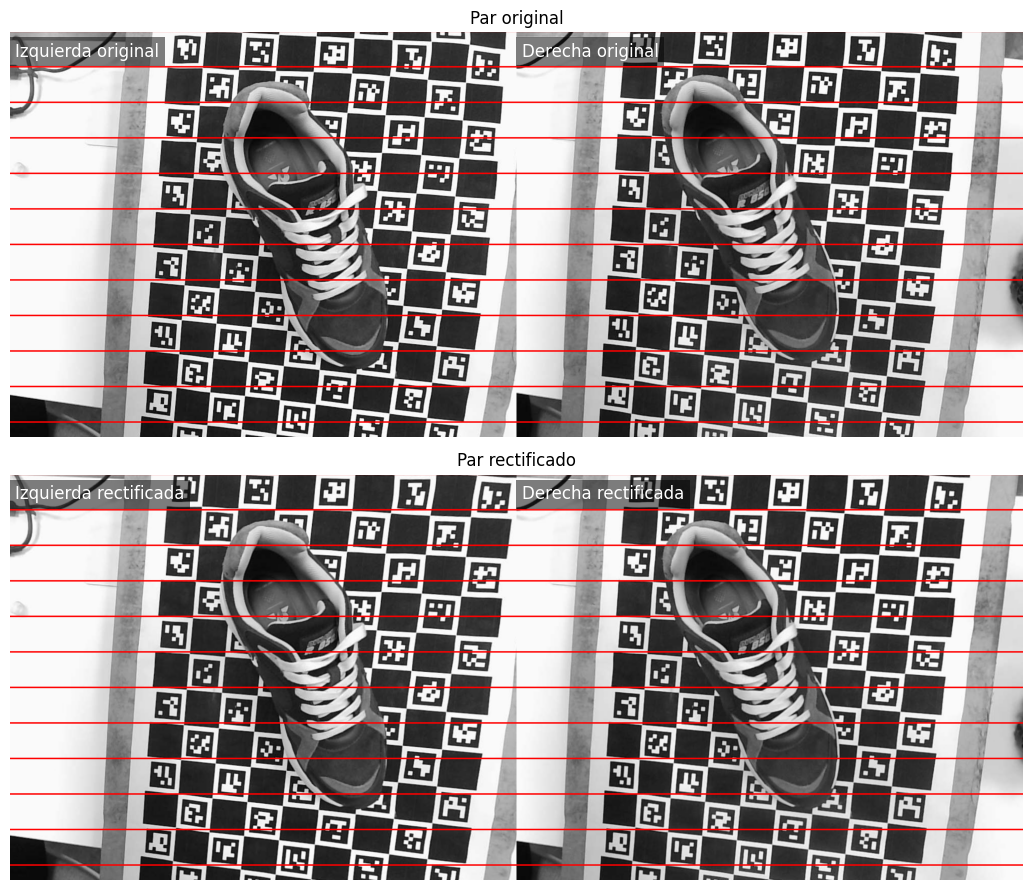

Par estéreo 10


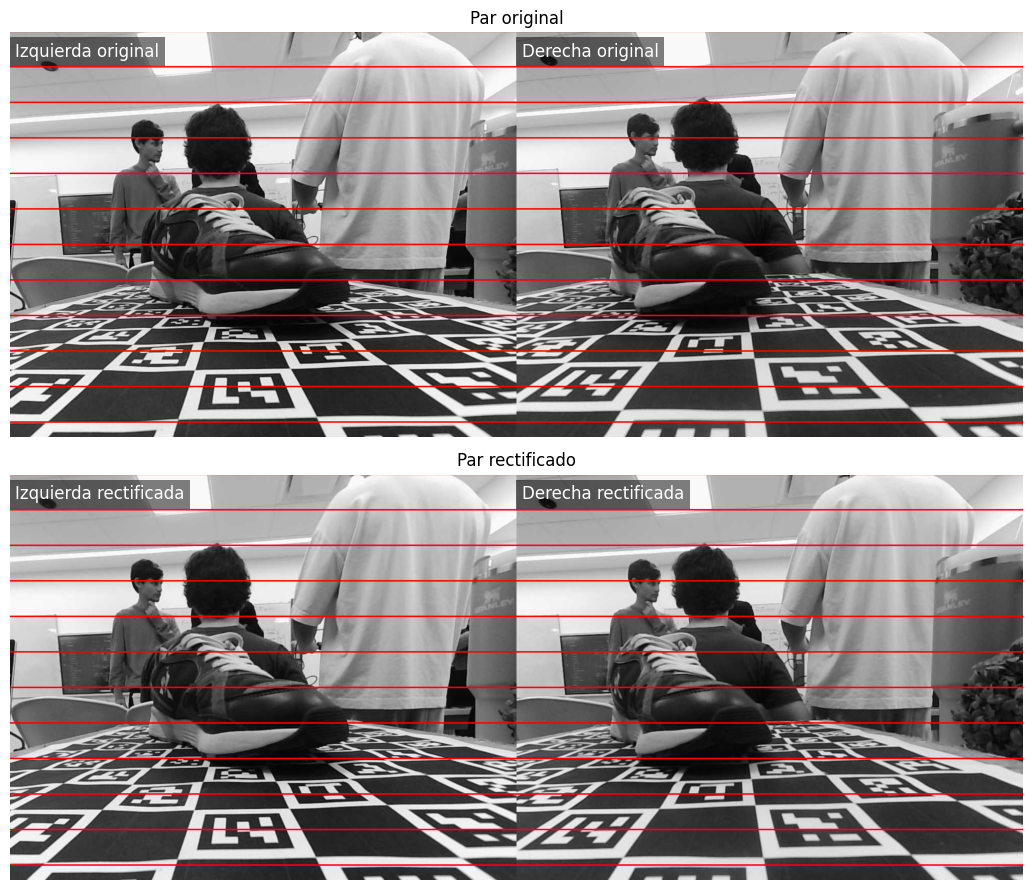

In [15]:
for indice in [0, 10]: # Mostramos dos pares estéreo de ejemplo
    img_izq = cv2.imread(os.path.join(CARPETA_CAPTURAS, f"left_{indice}.jpg"))
    img_der = cv2.imread(os.path.join(CARPETA_CAPTURAS, f"right_{indice}.jpg"))

    print(f"Par estéreo {indice}")
    utils.graficar_rectificacion(img_izq, img_der, rect, recorte = (50, 850, 550, 1550))

Las imágenes originales y rectificadas son similares, lo cual es consistente con la rotación relativa estimada entre las cámaras. Esta matriz es cercana a la identidad e indica que sus orientaciones ya eran muy parecidas antes de rectificar. Por este motivo, la transformación no produce un cambio marcado en la escena, aunque pueden observarse ajustes en los bordes y en el encuadre debidos a la corrección de distorsión y a la nueva proyección.

# ACA ESTA LO ANTERIRO ----------------------------------------------------------

### Estimación del tamaño del cuadrado
<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
OpenCV necesita el tamaño real del cuadrado del tablero para que la calibración quede en milímetros. Como no lo conocíamos, calibramos primero con un cuadrado de <strong>1</strong> (sin unidades): así el baseline queda expresado en "cuadrados". Comparándolo con el baseline de la calibración de `calib-stereo` (59.838 mm), despejamos el lado del cuadrado en mm.


In [8]:
# # Calibramos con cuadrado = 1: el baseline queda medido en "cuadrados"
# obj_puntos_1, pts_izq_1, pts_der_1, img_size = utils.detectar_esquinas(CARPETA_CALIB, (9, 6), 1.0)
# calib_unitaria = utils.calibracion_estereo(obj_puntos_1, pts_izq_1, pts_der_1, img_size)

# baseline_cuadrados = np.linalg.norm(calib_unitaria["T"])   
# baseline_mm = np.linalg.norm(calib_pkl["T"])             

# print("Baseline en mm:", baseline_mm.round(4))

In [9]:
# # Si 2.137 cuadrados = 59.8382 mm, entonces 1 cuadrado = 59.8382 / 2.137 mm
# size_cuadrado_mm = baseline_mm / baseline_cuadrados
# print(f"Tamaño del cuadrado: {size_cuadrado_mm:.2f} mm")  

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Como se busca calcular la profundidad de cada pixel de la imagen izquierda, necesitamos encontrar el mismo punto en la derecha. Sabemos que ese punto, siguiendo la geometria epipolar, cae sobre la linea epipolar que, originalmente se encuentra inclinada y por la distorsion, curva, por lo que la busqueda es costosa. 
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Para ello, resulta util la rectificacion, con la cual se logra "girar" las camaras de forma que los planos imagen queden paralelos y las lineas epipolares horizontales y a la misma altura en ambas imagenes. Con esto, los puntos de la imagen izquierda se hallan a la misma altura en la derecha (en la misma fila), pero trasladados horizontalmente. Esto ultimo es la disparidad. 
</p>

In [10]:
# objetos_puntos, pts_izq, pts_der, img_size = utils.detectar_esquinas(CARPETA_CALIB, (9, 6), size_cuadrado_mm)
# calib = utils.calibracion_estereo(objetos_puntos, pts_izq, pts_der, img_size, True)
# rect = utils.rectificacion(calib_unitaria)

In [11]:
# # Verificamos la rectificacion
# img_izq = cv2.imread(os.path.join(CARPETA_CAPTURAS, "left_0.jpg"))
# img_der = cv2.imread(os.path.join(CARPETA_CAPTURAS, "right_0.jpg"))
# utils.graficar_rectificacion(img_izq, img_der, rect, recorte = (50, 850, 550, 1550), paso = 30, grosor = 2) 

### ***2. Disparidad, reconstrucción local y pose de las cámaras***
<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Una vez calibrado el sistema y rectificadas las imágenes, el siguiente paso consiste en recuperar la estructura 3D de la escena. Para cada par estéreo calcularemos un mapa de disparidad, a partir del cual obtendremos una nube de puntos local. Luego estimaremos la pose de la cámara respecto del tablero de referencia para expresar los puntos en un sistema de coordenadas común a todas las capturas.
</p>

#### *Stereo Matching*: Cálculo del mapa de disparidad

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
La rectificación permite buscar correspondencias sobre una misma fila de las imágenes izquierda y derecha. Para un punto visible en ambas, la disparidad se define como la diferencia entre sus coordenadas horizontales:
</p>

$$
d(u,v) = u_{\mathrm{izq}} - u_{\mathrm{der}}
$$

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Por otro lado, la profundidad se relaciona con la disparidad mediante:
</p>

$$
Z = \frac{f \cdot B}{d}
$$

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
donde <i>f</i> es la distancia focal de la cámara rectificada en píxeles y <i>B</i> es el <i>baseline</i>. Esta relación muestra que la profundidad es inversamente proporcional a la disparidad: los puntos cercanos presentan mayor disparidad, mientras que los más lejanos presentan menor disparidad.
</p>


<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Como primera aproximación utilizaremos SGBM. Este método compara regiones de ambas imágenes y combina los costos de correspondencia en varias direcciones, favoreciendo una solución espacialmente coherente.
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Comenzaremos con un par representativo para inspeccionar el mapa obtenido y ajustar los parámetros antes de extender el procedimiento al resto de las capturas. Tendremos en cuenta que las oclusiones, las regiones con poca textura y los patrones repetitivos pueden generar correspondencias incorrectas o disparidades inválidas.
</p>

In [12]:
# Cargamos un par de ejemplo y lo rectificamos
indice = 0

img_izq = cv2.imread(os.path.join(CARPETA_CAPTURAS, f"left_{indice}.jpg"))
img_der = cv2.imread(os.path.join(CARPETA_CAPTURAS, f"right_{indice}.jpg"))

img_izq_rect, img_der_rect = utils.rectificar(img_izq, img_der, rect) # Usamos imagenes completas

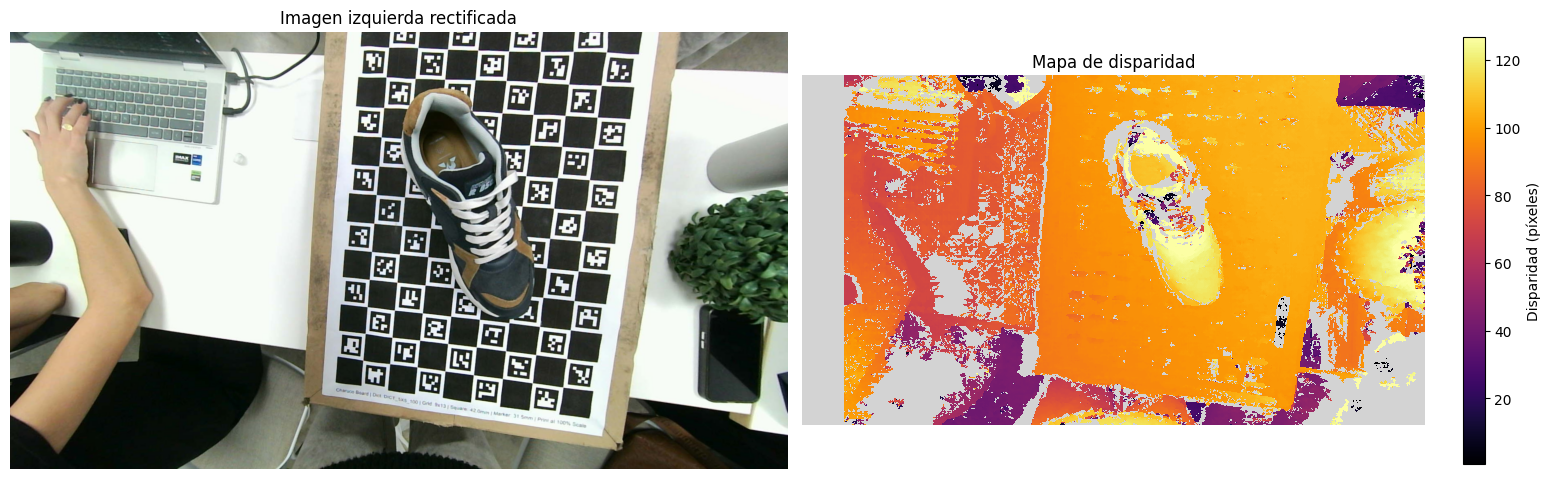

In [13]:
# Calculamos disparidad
disparidad = utils.calcular_disparidad(img_izq_rect, img_der_rect)

utils.graficar_disparidad(img_izq_rect, disparidad)

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Con SGBM logramos distinguir la zapatilla del tablero, aunque todavía hay ruido y zonas sin disparidades válidas. Para evaluar otras opciones, usaremos <code>stereodemo</code>. Compararemos SGBM y CREStereo sobre los mismos pares rectificados y ajustaremos sus parámetros, observando los mapas de disparidad y las nubes de puntos para elegir cómo continuar la reconstrucción.
</p>

In [ ]:
#import json
#from pathlib import Path
#
#carpeta_demo = Path("../data/prueba_stereodemo")
#carpeta_demo.mkdir(parents=True, exist_ok=True)
#
#for nombre, imagen in [
#    ("left_0.png", img_izq_rect),
#    ("right_0.png", img_der_rect),
#]:
#    if not cv2.imwrite(str(carpeta_demo / nombre), imagen):
#        raise RuntimeError(f"No se pudo guardar {nombre}")
#
## Parámetros de las cámaras rectificadas
#P1 = rect["P_izq"]
#P2 = rect["P_der"]
#alto, ancho = img_izq_rect.shape[:2]
#
## Separación horizontal del sistema rectificado, de mm a metros
#baseline_rect_mm = abs(P2[0, 3] / P2[0, 0])
#
#configuracion = {
#    "width": ancho,
#    "height": alto,
#    "baseline_meters": float(baseline_rect_mm / 1000),
#    "fx": float(P1[0, 0]),
#    "fy": float(P1[1, 1]),
#    "cx0": float(P1[0, 2]),
#    "cx1": float(P2[0, 2]),
#    "cy": float(P1[1, 2]),
#    "depth_range": [0.05, 20.0],
#    "left_image_rect_normalized": [0, 0, 1, 1],
#}
#
#with open(carpeta_demo / "stereodemo_calibration.json", "w", encoding="utf-8") as archivo:
#    json.dump(configuracion, archivo, indent=4)

In [ ]:
from ipywidgets import interact_manual, IntSlider

def probar_sgbm(num_disparidades=128, tam_bloque=7, uniqueness=7, speckle_window=512, speckle_range=64):
    gris_izq = cv2.cvtColor(img_izq_rect, cv2.COLOR_BGR2GRAY)
    gris_der = cv2.cvtColor(img_der_rect, cv2.COLOR_BGR2GRAY)

    stereo = cv2.StereoSGBM_create(minDisparity=0, numDisparities=num_disparidades, blockSize=tam_bloque)
    stereo.setP1(8 * tam_bloque**2)
    stereo.setP2(32 * tam_bloque**2)
    stereo.setUniquenessRatio(uniqueness)
    stereo.setSpeckleWindowSize(speckle_window)
    stereo.setSpeckleRange(speckle_range)
    stereo.setDisp12MaxDiff(1)

    disparidad = stereo.compute(gris_izq, gris_der).astype(np.float32) / 16.0
    validos = 100 * np.mean(disparidad > 0)
    print(f"Píxeles con disparidad válida: {validos:.1f}%")
    utils.graficar_disparidad(img_izq_rect, disparidad)

interact_manual(
    probar_sgbm,
    num_disparidades=IntSlider(value=128, min=16, max=256, step=16),
    tam_bloque=IntSlider(value=7, min=3, max=15, step=2),
    uniqueness=IntSlider(value=7, min=0, max=20, step=1),
    speckle_window=IntSlider(value=512, min=0, max=1000, step=50),
    speckle_range=IntSlider(value=64, min=1, max=128, step=1),
);

interactive(children=(IntSlider(value=128, description='num_disparidades', max=256, min=16, step=16), IntSlide…

#### *Construcción de la nube de puntos*

Puntos en la nube local: 1,492,583


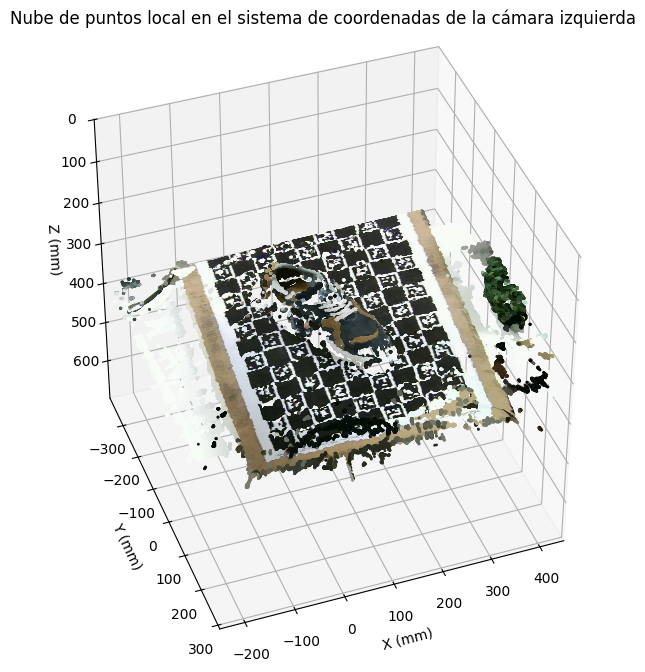

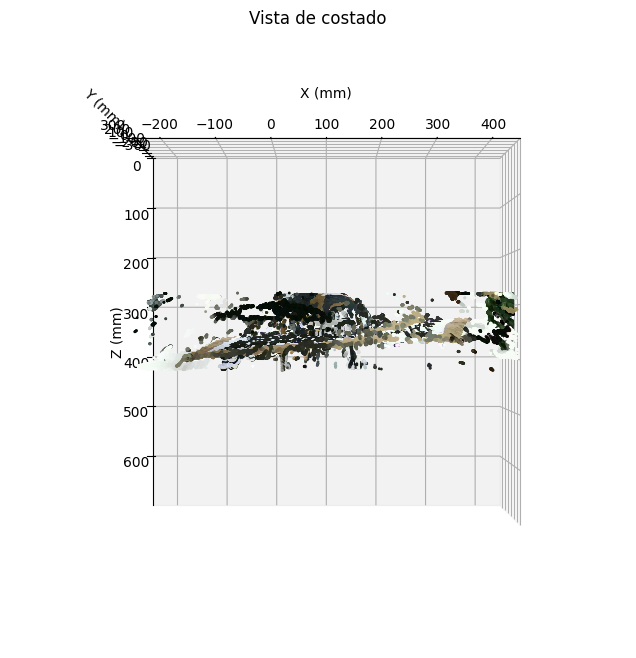

In [35]:
puntos_3d, colores = utils.nube_de_puntos_local(disparidad, img_izq_rect, rect["Q"])
print(f'Puntos en la nube local: {len(puntos_3d):,}')

# Región alrededor del tablero, para el par 0 (en mm, sistema de la cámara)
region_tablero = ((-250, 450), (-450, 300), (0, 420))

utils.graficar_nube_de_puntos(puntos_3d, colores, limites = region_tablero)                                     # oblicua
utils.graficar_nube_de_puntos(puntos_3d, colores, limites = region_tablero, elev = 180, azim = -90, titulo = "Vista de costado")   # se ve el relieve


#### *Pose de la cámara*

<p style="text-align: justify; text-justify: inter-word font-size: 16px"> 
Para la estimación de la pose de la cámara, debemos conocer la información precisa sobre el ChArUco utilizado durante la calibración, sobre el cual se apoyaron los objetos cuya nube de puntos se busca reconstruir.
</p>
 
<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Para ello, podemos observar los datos ubicados en el borde inferior del mismo, visibles en una de las imágenes tomadas
</p>

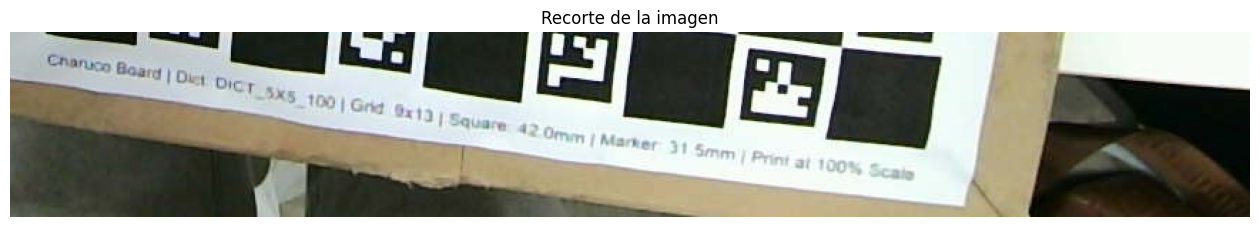

In [44]:
img = cv2.imread(os.path.join(CARPETA_CAPTURAS, "left_0.jpg"))
# Definimos la zona de interés (donde está la información)
recorte = img[870:1000, 780:1650]

plt.figure(figsize = (16, 8))
plt.imshow(cv2.cvtColor(recorte, cv2.COLOR_BGR2RGB))
plt.title("Recorte de la imagen")
plt.axis("off")
plt.show()

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
La función <code>solvePnP</code> estima la rotación <i>R</i> y la traslación <i>t</i> que llevan un punto expresado en el sistema del ChArUco (el mundo) al sistema de la cámara:
</p>

$$
X_{\mathrm{cam}} = R \, X_{\mathrm{mundo}} + t
$$

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
En su propio sistema de coordenadas, la cámara se encuentra en el origen, es decir, <i>X</i><sub>cam</sub> = (0, 0, 0). Por lo tanto, su posición <i>C</i> en el mundo es el punto que cumple:
</p>

$$
0 = R \, C + t \quad \Rightarrow \quad C = -R^{-1} t = -R^{T} t
$$

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Esta misma relación, aplicada a todos los puntos de la nube local, es la que permite llevarlos al sistema global mediante <i>X</i><sub>mundo</sub> = <i>R</i><sup>T</sup>(<i>X</i><sub>cam</sub> − <i>t</i>).
</p>


In [51]:
charuco, charuco_marcadores, detector = utils.analizar_charuco()
K_rectificado = rect["P_izq"][:,:3]

pose_camara = utils.estimar_pose_camara(img_izq_rect, K_rectificado, charuco, charuco_marcadores, detector)
print(f"Método: {pose_camara['metodo']}, Puntos: {pose_camara['n_puntos']}, 'Error de reproyección: {pose_camara['error_reproyeccion']:.4f} pf")
print('Posición de la cámara respecto al mundo (en mm):', (-pose_camara["R"].T @ pose_camara["t"]).ravel().round(1))

Método: charuco, Puntos: 48, 'Error de reproyección: 1.0836 pf
Posición de la cámara respecto al mundo (en mm): [ 108.7  317.5 -354.7]


In [ ]:
nubes_mundo, colores_mundo, poses = [], [], []

for indice in range(38):
    # Definimos para cada captura, la vista izquierda y derecha y rectificamos
    img_izq = cv2.imread(os.path.join(CARPETA_CAPTURAS, f"left_{indice}.jpg"))
    img_der = cv2.imread(os.path.join(CARPETA_CAPTURAS, f"right_{indice}.jpg"))
    img_izq_rect, img_der_rect = utils.rectificar(img_izq, img_der, rect)

    # Pose: si no se detecta el ChArUco, o el error es muy grande, salteamos la captura
    pose = utils.estimar_pose_camara(img_izq_rect, K_rectificado, charuco, charuco_marcadores, detector)
    if pose is None or pose["error_reproyeccion"] > 5:
        print(f"Captura {indice}: sin pose confiable, se descarta")
        continue

    # Disparidad -> nube local -> mundo
    disparidad = utils.calcular_disparidad(img_izq_rect, img_der_rect, 176, 7)
    puntos_3d, colores = utils.nube_de_puntos_local(disparidad, img_izq_rect, rect["Q"])
    puntos_mundo = utils.transformar_nube_a_mundo(puntos_3d, pose["R"], pose["t"])

    nubes_mundo.append(puntos_mundo.astype(np.float32))
    colores_mundo.append(colores.astype(np.float32))
    poses.append({"indice": indice, **pose})
    print(f"Captura {indice}: {pose['metodo']}, error {pose['error_reproyeccion']:.2f} px, {len(puntos_mundo):,} puntos")

# Nube global: todas las nubes juntas en el sistema del tablero
nube_global = np.vstack(nubes_mundo)
colores_global = np.vstack(colores_mundo)
print(f"\nCapturas usadas: {len(poses)} de 38")
print(f"Puntos en la nube global: {len(nube_global):,}")

Captura 0: charuco, error 1.08 px, 1,458,390 puntos
Captura 1: charuco, error 1.18 px, 1,371,062 puntos
Captura 2: charuco, error 1.38 px, 1,273,473 puntos
Captura 3: charuco, error 1.78 px, 1,229,500 puntos
Captura 4: charuco, error 2.27 px, 1,106,407 puntos
Captura 5: charuco, error 1.72 px, 1,219,058 puntos
Captura 6: charuco, error 1.68 px, 1,090,785 puntos
Captura 7: charuco, error 2.68 px, 960,960 puntos
Captura 8: marcadores, error 2.63 px, 879,596 puntos
Captura 9: marcadores, error 4.24 px, 601,912 puntos
Captura 10: marcadores, error 3.71 px, 672,912 puntos
Captura 11: marcadores, error 3.38 px, 662,588 puntos
Captura 12: marcadores, error 4.88 px, 543,843 puntos
Captura 13: sin pose confiable, se descarta
Captura 14: sin pose confiable, se descarta
Captura 15: marcadores, error 4.40 px, 769,447 puntos
Captura 16: sin pose confiable, se descarta
Captura 17: charuco, error 1.32 px, 965,158 puntos
Captura 18: charuco, error 1.03 px, 1,161,573 puntos
Captura 19: charuco, error 2

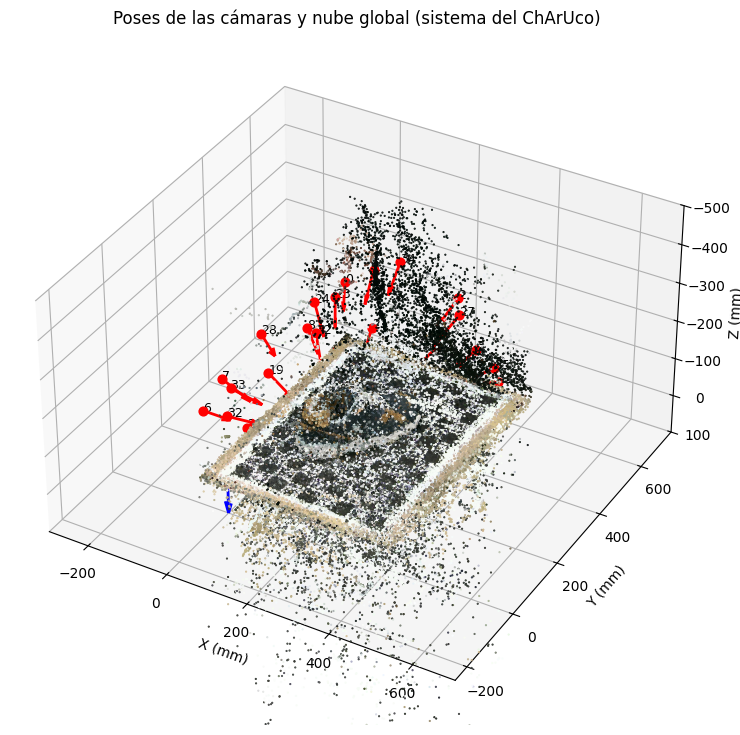

In [60]:
utils.graficar_poses(nube_global, colores_global, poses)